In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly as px
import tensorflow as tf
import regex as re

In [2]:
dataset_train = pd.read_csv(r'C:\Projects_ciência_dados\TITANIC\train.csv')

In [3]:
dataset_test = pd.read_csv(r"C:\Projects_ciência_dados\TITANIC\test.csv")

##### Inicialmente tinha dado erro nessas leituras, pois  o python estava entendendo as barras invertidas como caracteres especiais. Para resolver, basta colocar o r antes das aspas

In [4]:
dataset_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
dataset_train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [6]:
dataset_train.shape

(891, 12)

In [7]:
dataset_train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [8]:
dataset_train['Embarked'].mode()[0]

'S'

In [9]:
dataset_train.loc[dataset_train["Embarked"].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


In [10]:
dataset_train.drop([61,829], inplace=True)

In [11]:
type(dataset_train["Embarked"])

pandas.core.series.Series

In [12]:
#dataset_train.loc[dataset_train["Embarked"].isnull()] = 'S'

In [13]:
#dataset_train.loc[dataset_train["Age"] > 0, "Age"].mean()

In [14]:
dataset_train.loc[dataset_train["Age"].isnull(), "Age"] = 29.69

##### Não tem mais idade nula

In [15]:
dataset_train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

##### Não tem mais idade menor que 0

In [16]:
#dataset_train.loc[dataset_train["Age"] < 0, "Age"].sum()

##### Exlusão da coluna cabine. Justificativa: apresenta 77% dos dados faltantes

In [17]:
dataset_train = dataset_train.drop("Cabin", axis=1)

In [18]:
dataset_train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [19]:
dataset_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.0500,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.00,0,0,211536,13.0000,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.00,0,0,112053,30.0000,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,29.69,1,2,W./C. 6607,23.4500,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.00,0,0,111369,30.0000,C


In [20]:
dataset_train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000,889.000000
mean,446.000000,0.382452,2.311586,29.651631,0.524184,0.382452,32.096681
std,256.998173,0.486260,0.834700,12.968360,1.103705,0.806761,49.697504
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,224.000000,0.000000,2.000000,22.000000,0.000000,0.000000,7.895800
50%,446.000000,0.000000,3.000000,29.690000,0.000000,0.000000,14.454200
75%,668.000000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [21]:
dataset_train.loc[dataset_train["Age"] == 0.42]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
803,804,1,3,"Thomas, Master. Assad Alexander",male,0.42,0,1,2625,8.5167,C


##### Quantidade das pessoas menores que 10 anos que sobreviveram

In [22]:
#dataset_train.loc[dataset_train["Age"] <= 10, "Survived"].count()

##### Quantidade das pessoa menores que 10 anos. Ou seja, todas sobreviveram

In [23]:
#dataset_train.loc[dataset_train["Age"] <= 10, "Age"].count()

In [24]:
Sobreviventes = dataset_train.loc[dataset_train["Survived"] == 1, "Survived"].count()

In [25]:
Sobreviventes

np.int64(340)

In [26]:
NSobreviventes = dataset_train.loc[dataset_train["Survived"] == 0, "Survived"].count()

In [27]:
Sobreviventes+NSobreviventes

np.int64(889)

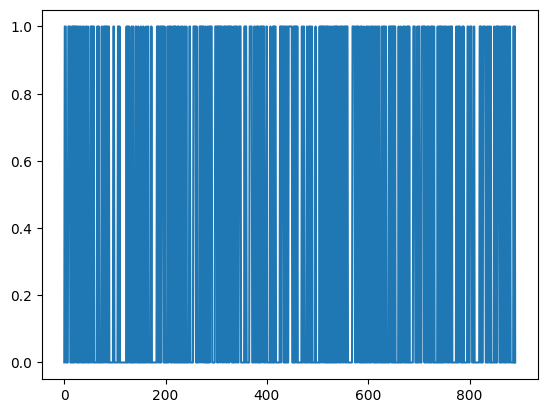

In [28]:
plt.plot(dataset_train["Survived"])

In [29]:
qtd_mulheres_sobreviveram = dataset_train.loc[(dataset_train["Sex"] == "female") & (dataset_train["Survived"] == 1)].count()

In [30]:
qtd_mulheres_sobreviveram

PassengerId    231
Survived       231
Pclass         231
Name           231
Sex            231
Age            231
SibSp          231
Parch          231
Ticket         231
Fare           231
Embarked       231
dtype: int64

In [31]:
qtd_homens_sobreviveram = dataset_train.loc[dataset_train["Sex"] == 'male', "Survived"].count()

In [32]:
qtd_homens_sobreviveram

np.int64(577)

In [33]:
print(f"Porcentagem de mulheres que sobreviveram: {qtd_mulheres_sobreviveram/Sobreviventes}")

Porcentagem de mulheres que sobreviveram: PassengerId    0.679412
Survived       0.679412
Pclass         0.679412
Name           0.679412
Sex            0.679412
Age            0.679412
SibSp          0.679412
Parch          0.679412
Ticket         0.679412
Fare           0.679412
Embarked       0.679412
dtype: float64


In [34]:
dataset_train["Sex"]

0        male
1      female
2      female
3      female
4        male
        ...  
886      male
887    female
888    female
889      male
890      male
Name: Sex, Length: 889, dtype: object

### Ler sobre as colunas do dataset
### Entender a diferença de estrutura entre os dois locs
### continuar o pré-processamento

In [35]:
dataset_train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')

In [36]:
dataset_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.00,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.0500,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.00,0,0,211536,13.0000,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.00,0,0,112053,30.0000,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,29.69,1,2,W./C. 6607,23.4500,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.00,0,0,111369,30.0000,C


##### Número de pessoas que tinham pais/filhos a bordo do titanic e morreram

In [37]:
qtd_p_a_m = dataset_train.loc[(dataset_train["Parch"] > 0) & (dataset_train["Survived"] == 0)]
qtd_p_a_m.count()

PassengerId    104
Survived       104
Pclass         104
Name           104
Sex            104
Age            104
SibSp          104
Parch          104
Ticket         104
Fare           104
Embarked       104
dtype: int64

##### Tinha pais e filhos a bordo e não morreram

In [38]:
qtd_p_a_Nm = dataset_train.loc[(dataset_train["Parch"] > 0) & (dataset_train["Survived"] == 1)]
qtd_p_a_Nm.count()

PassengerId    109
Survived       109
Pclass         109
Name           109
Sex            109
Age            109
SibSp          109
Parch          109
Ticket         109
Fare           109
Embarked       109
dtype: int64

In [39]:
np.unique(dataset_train["Ticket"], return_counts=True)

(array(['110152', '110413', '110465', '110564', '110813', '111240',
        '111320', '111361', '111369', '111426', '111427', '111428',
        '112050', '112052', '112053', '112058', '112059', '112277',
        '112379', '113028', '113043', '113050', '113051', '113055',
        '113056', '113059', '113501', '113503', '113505', '113509',
        '113510', '113514', '113760', '113767', '113773', '113776',
        '113781', '113783', '113784', '113786', '113787', '113788',
        '113789', '113792', '113794', '113796', '113798', '113800',
        '113803', '113804', '113806', '113807', '11668', '11751', '11752',
        '11753', '11755', '11765', '11767', '11769', '11771', '11774',
        '11813', '11967', '12233', '12460', '12749', '13049', '13213',
        '13214', '13502', '13507', '13509', '13567', '13568', '14311',
        '14312', '14313', '14973', '1601', '16966', '16988', '17421',
        '17453', '17463', '17464', '17465', '17466', '17474', '17764',
        '19877', '19928', '

In [40]:
dataset_train["Title_Name"] = dataset_train["Name"].str.extract(r',\s*([^\.]+)\.')

In [41]:
dataset_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Title_Name
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Mr


##### Extrai os prefixos dos tickets, que podem indicar classe social, mas vou inicialmente testar sem eles

In [42]:
#dataset_train["TicketPrefix"] = dataset_train["Ticket"].str.split().str[0]

In [43]:
dataset_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Title_Name
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Mr


In [44]:
dataset_train = dataset_train.drop(["Ticket","Name","PassengerId"], axis=1) # Se for excluir mais de uma coluna, coloca em forma de lista

In [45]:
dataset_train.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked', 'Title_Name'],
      dtype='object')

In [46]:
negativas = dataset_train.select_dtypes(include=["int64", "float64"])
(negativas<0).any().sum()

np.int64(0)

In [47]:
x_previsores = dataset_train.iloc[:,1:9]#.values
x_previsores

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title_Name
0,3,male,22.00,1,0,7.2500,S,Mr
1,1,female,38.00,1,0,71.2833,C,Mrs
2,3,female,26.00,0,0,7.9250,S,Miss
3,1,female,35.00,1,0,53.1000,S,Mrs
4,3,male,35.00,0,0,8.0500,S,Mr
...,...,...,...,...,...,...,...,...
886,2,male,27.00,0,0,13.0000,S,Rev
887,1,female,19.00,0,0,30.0000,S,Miss
888,3,female,29.69,1,2,23.4500,S,Miss
889,1,male,26.00,0,0,30.0000,C,Mr


In [48]:
y_classe = dataset_train.iloc[:,0].values
y_classe

array([0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,

### Importante: analisar se tem categóricas apenas no x_previsores, pois é só ele que vai passar pelo OneHotEncoder

In [49]:
categoricas = x_previsores.select_dtypes(include=["object"])
indices_categoricos = [x_previsores.columns.get_loc(i) for i in categoricas]

In [50]:
indices_categoricos

[1, 6, 7]

In [51]:
dataset_train.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked', 'Title_Name'],
      dtype='object')

In [52]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [53]:
onehot = ColumnTransformer(transformers=[("Onehot", OneHotEncoder(handle_unknown='ignore'), indices_categoricos)], remainder="passthrough")

In [54]:
x_previsores = onehot.fit_transform(x_previsores)

In [55]:
x_previsores.shape

(889, 27)

In [56]:
from sklearn.preprocessing import StandardScaler
standard = StandardScaler(with_mean=False)
x_previsores = standard.fit_transform(x_previsores)

In [57]:
from sklearn.model_selection import train_test_split

In [58]:
x_treinamento, x_test, y_treinamento, y_test = train_test_split(x_previsores, y_classe, test_size=0.2, random_state=0)

###### Pré processamento concluído para o dataset de treino, precisa fazer o msm para o de teste

In [59]:
dataset_test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [60]:
dataset_test.loc[dataset_test["Age"]>0, "Age"].mean()

np.float64(30.272590361445783)

In [61]:
dataset_test.loc[dataset_test["Age"]<=0, "Age"]=30.27

In [62]:
dataset_test.loc[dataset_test["Fare"]>0, "Fare"].mean()

np.float64(35.798885783132526)

In [63]:
dataset_test.loc[dataset_test["Fare"].isnull(), "Fare"] = 35.79 

In [64]:
dataset_test.shape

(418, 11)

In [65]:
dataset_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [66]:
dataset_test["Title_Name"] = dataset_test["Name"].str.extract(r',\s*([^\.]+)\.')

In [67]:
np.unique(dataset_test["Title_Name"], return_counts=True)

(array(['Col', 'Dona', 'Dr', 'Master', 'Miss', 'Mr', 'Mrs', 'Ms', 'Rev'],
       dtype=object),
 array([  2,   1,   1,  21,  78, 240,  72,   1,   2]))

In [68]:
dataset_test

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title_Name
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,Mr
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,Mrs
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,Mr
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,Mr
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,Mrs
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S,Mr
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C,Dona
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S,Mr
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S,Mr


In [69]:
dataset_test.columns

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked', 'Title_Name'],
      dtype='object')

In [70]:
dataset_test = dataset_test.drop(["Name","Ticket","Cabin"], axis=1)

In [71]:
dataset_test.columns

Index(['PassengerId', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked', 'Title_Name'],
      dtype='object')

In [72]:
dataset_test["Age"].isnull().sum()

np.int64(86)

In [73]:
dataset_test.loc[dataset_test["Age"] > 0, "Age"].mean()

np.float64(30.272590361445783)

In [74]:
dataset_test.loc[dataset_test["Age"].isnull(), "Age"] = 30.27

In [75]:
dataset_test.loc[dataset_test["Age"].isnull()]

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title_Name


In [76]:
numericas = dataset_test.select_dtypes(include=["int","float"])
(numericas<0).any().sum()

np.int64(0)

In [77]:
categoricas_test = dataset_test.select_dtypes(include=["object"])
indices_categoricos_test = [dataset_test.columns.get_loc(col) for col in categoricas_test]

In [78]:
indices_categoricos_test

[2, 7, 8]

In [79]:
dataset_test.columns

Index(['PassengerId', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked', 'Title_Name'],
      dtype='object')

In [80]:
dataset_test.isnull().sum()

PassengerId    0
Pclass         0
Sex            0
Age            0
SibSp          0
Parch          0
Fare           0
Embarked       0
Title_Name     0
dtype: int64

In [81]:
dataset_test.loc[dataset_test["Fare"].isnull()]

,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title_Name


In [82]:
#onehot = ColumnTransformer(transformers=[("Onehot", OneHotEncoder(), indices_categoricos_test)], remainder="passthrough")
dataset_test = onehot.transform(dataset_test)

In [83]:
dataset_test

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2734 stored elements and shape (418, 27)>

#### Para Encodar dataset train e test, só usa 1 OneHotEncoder. Usa a msm instâcia para os dois e usa como parâmetro do OneHotEncoder(handle_unknown='ignore') e no dataset de test usa o método transform, ao invés do fit_transform

In [84]:
dataset_test = standard.transform(dataset_test)

In [85]:
dataset_test

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 2734 stored elements and shape (418, 27)>

In [86]:
dataset_test_array_dense = dataset_test.toarray()

In [87]:
dataset_test_array_dense = pd.DataFrame(dataset_test_array_dense)
dataset_test_array_dense

,0,1,2,3,4,5,6,7,8,9,...,17,18,19,20,21,22,23,24,25,26
0,0.000000,2.095253,0.000000,3.555317,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,3.59613,2.661818,0.000000,0.000000,0.157626
1,2.095253,0.000000,0.000000,0.000000,2.238081,0.0,0.0,0.0,0.0,0.0,...,2.886424,0.0,0.0,0.0,0.0,3.59613,3.626245,0.906549,0.000000,0.140931
2,0.000000,2.095253,0.000000,3.555317,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,2.39742,4.783558,0.000000,0.000000,0.195039
3,0.000000,2.095253,0.000000,0.000000,2.238081,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,3.59613,2.083162,0.000000,0.000000,0.174403
4,2.095253,0.000000,0.000000,0.000000,2.238081,0.0,0.0,0.0,0.0,0.0,...,2.886424,0.0,0.0,0.0,0.0,3.59613,1.697391,0.906549,1.240223,0.247385
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,0.000000,2.095253,0.000000,0.000000,2.238081,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,3.59613,2.335456,0.000000,0.000000,0.162071
414,2.095253,0.000000,2.554345,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,1.19871,3.009012,0.000000,0.000000,2.192490
415,0.000000,2.095253,0.000000,0.000000,2.238081,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,3.59613,2.970435,0.000000,0.000000,0.145965
416,0.000000,2.095253,0.000000,0.000000,2.238081,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.0,0.0,0.0,0.0,3.59613,2.335456,0.000000,0.000000,0.162071


In [88]:
dataset_train.isnull().sum()

Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
Title_Name    0
dtype: int64

In [89]:
from sklearn.ensemble import RandomForestClassifier

arbols = RandomForestClassifier(n_estimators=200, max_features='log2', min_samples_leaf=5, min_samples_split=5, max_depth=10, max_leaf_nodes=50)

arbols.fit(x_treinamento, y_treinamento)

previsao = arbols.predict(dataset_test)

In [90]:
dataset_test_original = pd.read_csv(r"C:\Projects_ciência_dados\TITANIC\test.csv")

In [91]:
submissao = pd.DataFrame({
    "PassengerId":dataset_test_original["PassengerId"],
    "Survived":previsao
})

submissao.to_csv("submission.csv", index=False)

In [92]:
arvore = arbols.estimators_[0]

In [93]:
n_folhas = arvore.tree_.n_leaves
n_folhas

np.int64(29)

In [94]:
from sklearn.model_selection import cross_val_score

In [95]:
cross = cross_val_score(arbols,x_treinamento,y_treinamento, cv=5)

In [96]:
cross.mean()

np.float64(0.8453068058701863)

In [97]:
print(f"Acurácia: {cross}")

Acurácia: [0.83216783 0.88028169 0.82394366 0.80985915 0.88028169]


In [98]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [99]:
acuracia = accuracy_score(previsao, y_test)

ValueError: Found input variables with inconsistent numbers of samples: [418, 178]

In [ ]:
print(f"Acurácia_RF: {acuracia}")

Acurácia_RF: 0.7584269662921348


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

search = RandomizedSearchCV(
    RandomForestClassifier(random_state=0),
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    n_jobs=-1,
    scoring='accuracy'
)

search.fit(x_treinamento, y_treinamento)
print(search.best_params_)


{'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10}


In [ ]:
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
KNN = KNeighborsClassifier(n_neighbors=3)

KNN.fit(x_treinamento, y_treinamento)

previsao_KNN = KNN.predict(x_test)

In [ ]:
acuracia_KNN = accuracy_score(previsao_KNN, y_test)
print(acuracia_KNN) 

0.7471910112359551
